# Cohort quality control

Compare the measured coverage and sampled spectra of all 12 mice. The recorded
pixel coordinates define the coverage footprint. The boundary band includes
pixels within three pixels of unmeasured space, including holes. This is an
operational QC definition. Anatomical masks will require registered histology.

We sample up to 96 spectra per mouse from each of the boundary and interior
strata.

The plots help choose regions and features for later analysis.

In [6]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator

root = Path.cwd().resolve()
if not (root / "pyproject.toml").exists():
    root = root.parent
assert (root / "pyproject.toml").exists(), "Open the notebook from the repository."
sys.path.insert(0, str(root / "src"))

from cardiac_aging.inspection import inventory, load_config
from cardiac_aging.cohort_qc import inspect_mouse

config = load_config(root)
data = Path(config["data_dir"])
results = root / config["results_dir"]
results.mkdir(parents=True, exist_ok=True)
rows = inventory(data, root / config["sample_sheet"])

cohort = []
for row in rows:
    print(f"Reading mouse {row['measurement_id']}", flush=True)
    qc = inspect_mouse(data / row["imzml_filename"], row, config["random_seed"])
    cohort.append(qc)
summary = pd.DataFrame(qc["summary"] for qc in cohort)
summary.to_csv(results / "cohort_qc_summary.csv", index=False)
display(summary)

Reading mouse 1465
Reading mouse 1466
Reading mouse 1467
Reading mouse 1468
Reading mouse 1469
Reading mouse 1470
Reading mouse 1471
Reading mouse 1472
Reading mouse 1473
Reading mouse 1474
Reading mouse 1475
Reading mouse 1476


,measurement_id,animal_id,age_group,measured_pixels,edge_fraction,sampled_edge,sampled_interior,sampled_tic_cv,candidate_edge_median,candidate_interior_median
0,1465,Lux10,young,49973,0.061853,96,96,2.391566e-08,50.392430,29.059547
1,1466,Lux11,young,67228,0.098218,96,96,2.655064e-08,19.528646,27.462474
2,1467,Lux12,young,69540,0.081450,96,96,2.674119e-08,27.830935,33.052030
3,1468,Lux16,young,96297,0.045225,96,96,2.364536e-08,27.389548,24.529298
4,1469,Lux17,young,83903,0.056446,96,96,2.600548e-08,41.911399,44.422214
5,1470,Lux18,young,71670,0.077368,96,96,2.534443e-08,27.825289,39.391510
6,1471,Lux13,old,78259,0.052237,96,96,2.520473e-08,35.215040,30.425883
7,1472,Lux14,old,88747,0.068881,96,96,2.443114e-08,34.294953,25.417804
8,1473,Lux15,old,124191,0.063902,96,96,2.469869e-08,24.765054,38.875056
9,1474,Lux19,old,101798,0.116515,96,96,2.384959e-08,39.417078,40.520106


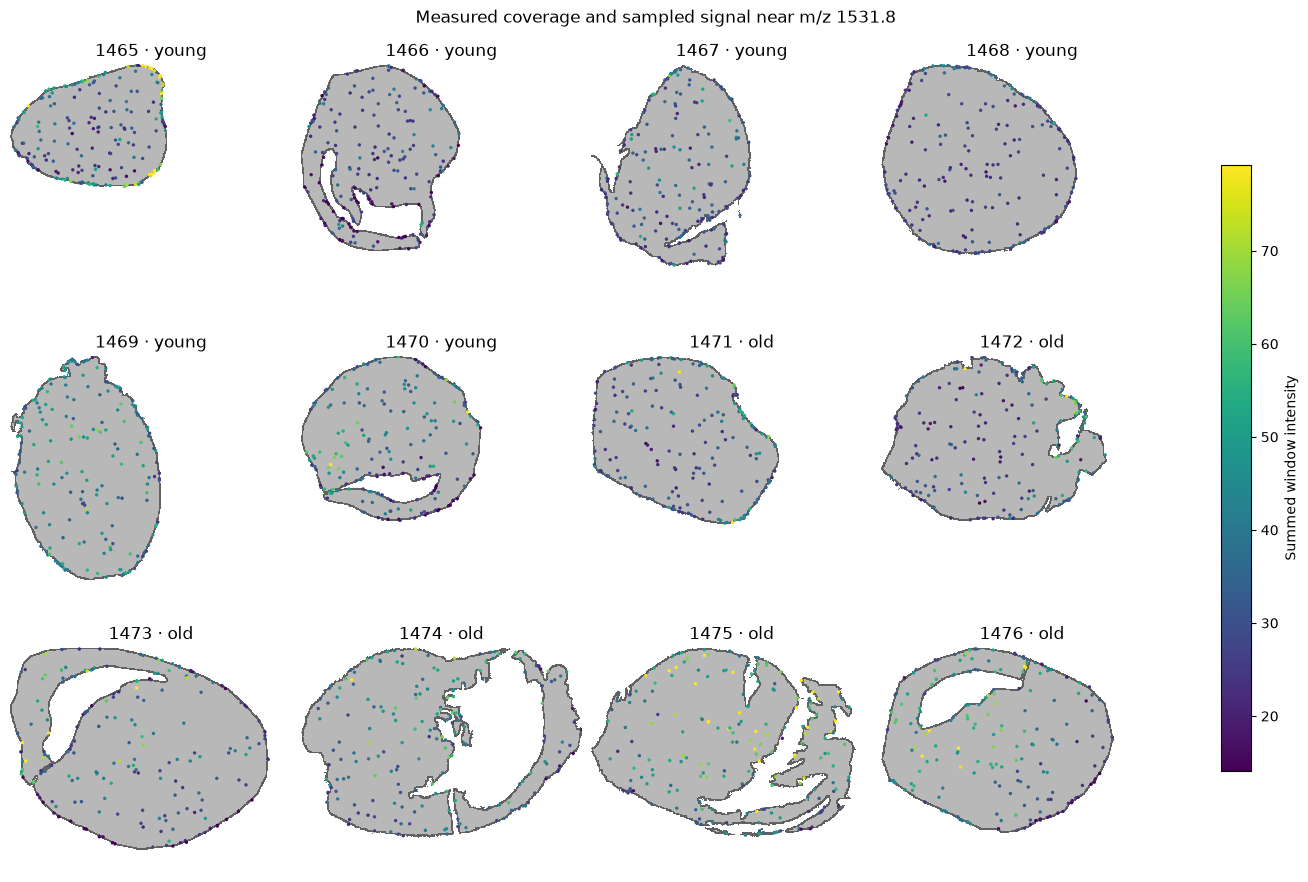

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(13, 9), layout="constrained")
all_signals = np.concatenate([qc["signal"] for qc in cohort])
norm = Normalize(*np.percentile(all_signals, [2, 98]), clip=True)
max_x = max(qc["mask"].shape[1] for qc in cohort)
max_y = max(qc["mask"].shape[0] for qc in cohort)
for ax, qc in zip(axes.flat, cohort):
    footprint = np.where(qc["mask"], np.where(qc["interior"], .72, .38), 1)
    ax.imshow(footprint, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    plot = ax.scatter(qc["x"], qc["y"], c=qc["signal"], norm=norm,
                      cmap="viridis", s=6, linewidths=0)
    ax.set(xlim=(-1, max_x), ylim=(max_y, -1))
    ax.set_title(f"{qc['summary']['measurement_id']} · {qc['summary']['age_group']}")
    ax.set_axis_off()
fig.suptitle("Measured coverage and sampled signal near m/z 1531.8")
fig.colorbar(plot, ax=axes, shrink=.7,
             label="Summed window intensity")
fig.savefig(results / "cohort_coverage_and_candidate.png", dpi=170)
plt.show()

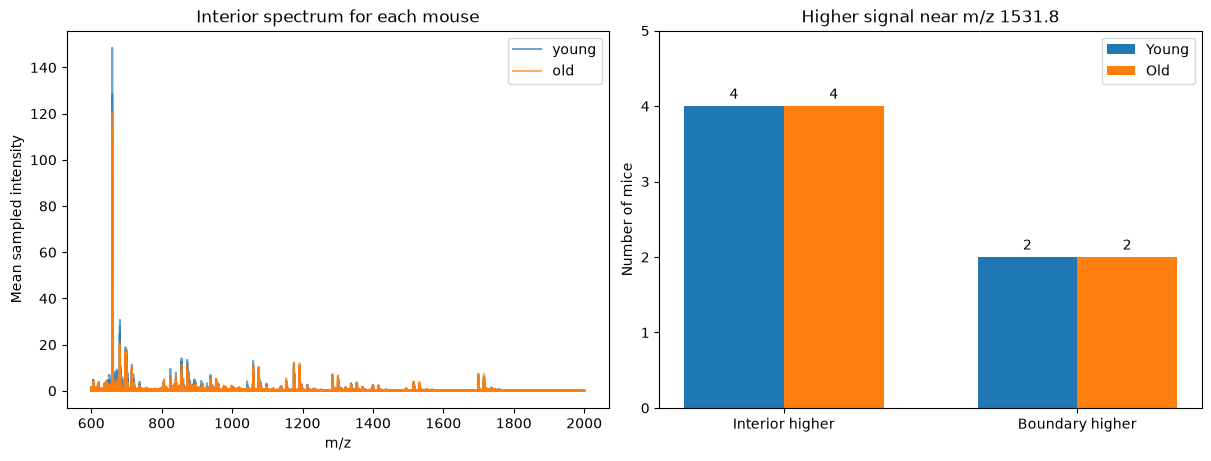

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
colors = {"young": "tab:blue", "old": "tab:orange"}
labelled = set()
for qc in cohort:
    group = qc["summary"]["age_group"]
    if qc["interior_spectrum"] is not None:
        axes[0].plot(qc["mz"], qc["interior_spectrum"], color=colors[group],
                     label=group if group not in labelled else None, alpha=.65)
        labelled.add(group)
axes[0].set(xlabel="m/z", ylabel="Mean sampled intensity",
            title="Interior spectrum for each mouse")
axes[0].legend()


interior = summary["candidate_interior_median"]
boundary = summary["candidate_edge_median"]

counts = (
    summary.assign(
        interior_higher=interior > boundary,
        boundary_higher=boundary > interior,
    )
    .groupby("age_group")[["interior_higher", "boundary_higher"]]
    .sum()
)

x = np.arange(2)
width = 0.34
ax = axes[1]

for offset, group in [(-width / 2, "young"), (width / 2, "old")]:
    bars = ax.bar(
        x + offset, counts.loc[group], width,
        label=group.capitalize(), color=colors[group],
    )
    ax.bar_label(bars, padding=3)

ax.set(
    xticks=x,
    xticklabels=["Interior higher", "Boundary higher"],
    ylabel="Number of mice",
    title="Higher signal near m/z 1531.8",
    ylim=(0, counts.to_numpy().max() + 1),
)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()

fig.savefig(results / "cohort_spectral_qc.png", dpi=170)
plt.show()

The candidate map shows individual sampled positions on a common color scale.
Compare the paired boundary and interior medians before choosing a region for
the age comparison. Next, match each histology image to its measurement ID and
record its stain and section relationship. Review the registration visually
before using tissue labels to extract regional molecular features.